**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
**Implementasi:** Iris Dataset <br>
By: TAP

**Tugas** <br>
Implementasikan kode program yang diberikan dengan dataset yang berbeda serta jelaskan apa yang Anda buat. Tugas dikumpulkan di hari Selasa, 3 Oktober 2026 jam 23.59 WIB di ecourse (baru).

In [3]:
%pip install tensorflow numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


### Instalasi Library

Pada praktikum ini digunakan beberapa library Python untuk membantu proses pembuatan Neural Network. TensorFlow digunakan untuk membangun model, NumPy untuk pengolahan data, Matplotlib untuk menampilkan grafik, dan Scikit-learn untuk mengambil serta membagi dataset Iris.

### 1. Memanggil dan Menyiapkan Dataset

Pada bagian ini saya menggunakan Iris Dataset sebagai pengganti Fashion MNIST. Dataset Iris berisi data pengukuran bunga yang terdiri dari empat fitur, yaitu sepal length, sepal width, petal length, dan petal width. Dataset ini memiliki tiga jenis bunga, yaitu Setosa, Versicolor, dan Virginica.

Data kemudian dibagi menjadi data training dan testing dengan perbandingan 80:20. Saya juga menggunakan StandardScaler untuk menyamakan skala nilai setiap fitur agar lebih mudah diproses oleh model Neural Network.

Jumlah seluruh data: 150
Jumlah data training: 120
Jumlah data testing: 30
Fitur dataset: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Jenis bunga: ['setosa' 'versicolor' 'virginica']


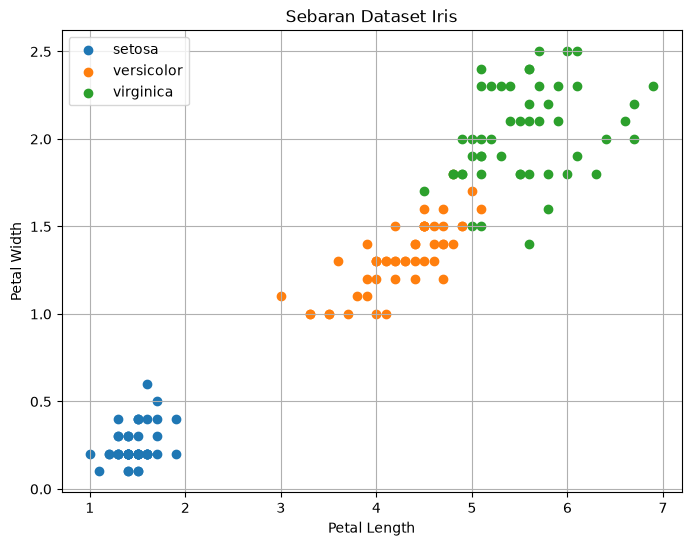

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset Iris
iris = load_iris()

X = iris.data
y = iris.target

class_names = iris.target_names
feature_names = iris.feature_names

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalisasi data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Menampilkan informasi dataset
print("Jumlah seluruh data:", len(X))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Fitur dataset:", feature_names)
print("Jenis bunga:", class_names)

# Melihat sebaran data
plt.figure(figsize=(8, 6))

for i, name in enumerate(class_names):
    plt.scatter(
        X[y == i, 2],
        X[y == i, 3],
        label=name
    )

plt.title("Sebaran Dataset Iris")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()
plt.grid()
plt.show()

### 2. Membuat Model Neural Network

Pada tahap ini saya membuat model Neural Network menggunakan Sequential. Model menerima empat input sesuai jumlah fitur pada dataset Iris. Hidden layer menggunakan 128 neuron dengan fungsi aktivasi ReLU, sedangkan output layer menggunakan tiga neuron dengan fungsi aktivasi Softmax karena terdapat tiga jenis bunga yang akan diprediksi.

In [6]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

# Membuat model Neural Network
model = Sequential([
    Input(shape=(4,)),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])

# Melihat ringkasan arsitektur model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,027 (4.01 KB)

 Trainable params: 1,027 (4.01 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Kompilasi dan Training Model

Setelah model dibuat, langkah berikutnya adalah melakukan kompilasi dan training. Optimizer yang digunakan adalah Adam, sedangkan fungsi loss menggunakan sparse categorical crossentropy karena model melakukan klasifikasi ke dalam tiga kelas. Model dilatih selama 10 epoch menggunakan data training yang sudah disiapkan sebelumnya.

In [7]:
# Kompilasi model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih model dengan data training
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.1458 - loss: 1.1044 - val_accuracy: 0.2500 - val_loss: 1.0749
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4792 - loss: 1.0233 - val_accuracy: 0.5417 - val_loss: 1.0022
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6146 - loss: 0.9491 - val_accuracy: 0.6250 - val_loss: 0.9365
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6979 - loss: 0.8817 - val_accuracy: 0.6250 - val_loss: 0.8777
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7188 - loss: 0.8209 - val_accuracy: 0.6667 - val_loss: 0.8255
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7917 - loss: 0.7663 - val_accuracy: 0.7083 - val_loss: 0.7792
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8229 - loss: 0.7176 - val_accuracy: 0.7083 - val_loss: 0.7383
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8333 - loss: 0.6744 - val_accuracy: 0.7083 - val_loss: 0.7022


### 4. Evaluasi Model

Setelah proses training selesai, model diuji menggunakan data testing. Evaluasi dilakukan untuk mengetahui kemampuan model dalam memprediksi jenis bunga yang belum digunakan saat proses training. Hasil evaluasi ditampilkan dalam bentuk nilai loss dan accuracy.

In [8]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f'\nTest accuracy: {test_acc}')
print(f'Test accuracy (%): {test_acc * 100:.2f}%')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8000 - loss: 0.6241

Test accuracy: 0.800000011920929
Test accuracy (%): 80.00%


### 5. Visualisasi Accuracy dan Loss

Pada bagian ini saya menampilkan grafik accuracy dan loss untuk melihat perkembangan model selama proses training. Grafik accuracy menunjukkan tingkat ketepatan model dalam memprediksi data, sedangkan grafik loss menunjukkan tingkat kesalahan model. Dari kedua grafik tersebut dapat dilihat bagaimana proses pembelajaran model berlangsung.

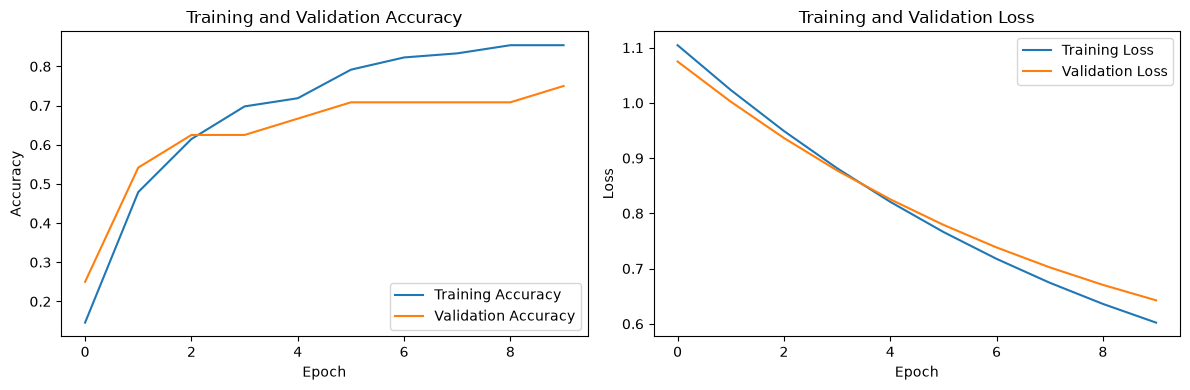

In [9]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

### 6. Melakukan Prediksi

Pada tahap terakhir, model digunakan untuk memprediksi jenis bunga berdasarkan data testing. Hasil prediksi kemudian dibandingkan dengan jenis bunga sebenarnya. Dengan demikian, dapat diketahui apakah model berhasil mengenali jenis bunga berdasarkan empat fitur yang diberikan.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Data ke-1 | Prediksi: setosa | Asli: setosa
Data ke-2 | Prediksi: virginica | Asli: virginica
Data ke-3 | Prediksi: versicolor | Asli: versicolor
Data ke-4 | Prediksi: versicolor | Asli: versicolor
Data ke-5 | Prediksi: setosa | Asli: setosa
Data ke-6 | Prediksi: virginica | Asli: versicolor
Data ke-7 | Prediksi: setosa | Asli: setosa
Data ke-8 | Prediksi: setosa | Asli: setosa
Data ke-9 | Prediksi: virginica | Asli: virginica
Data ke-10 | Prediksi: versicolor | Asli: versicolor
Data ke-11 | Prediksi: virginica | Asli: virginica
Data ke-12 | Prediksi: virginica | Asli: virginica
Data ke-13 | Prediksi: virginica | Asli: virginica
Data ke-14 | Prediksi: virginica | Asli: versicolor
Data ke-15 | Prediksi: setosa | Asli: setosa
Data ke-16 | Prediksi: setosa | Asli: setosa
Data ke-17 | Prediksi: setosa | Asli: setosa
Data ke-18 | Prediksi: versicolor | Asli: versicolor
Data ke-19 | Prediksi: virginica | Asli: versicolor
Data ke-20 | Prediksi: virginica 

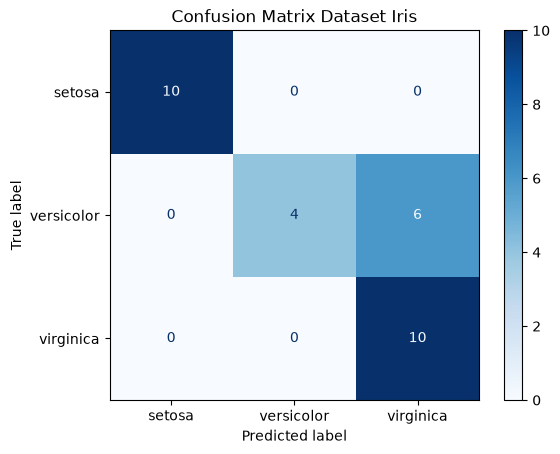

In [10]:
# Melakukan prediksi pada data pengujian
import numpy as np

predictions = model.predict(X_test)

# Menampilkan hasil prediksi
for i in range(25):
    predicted_label = np.argmax(predictions[i])
    actual_label = y_test[i]

    print(
        f"Data ke-{i+1} | "
        f"Prediksi: {class_names[predicted_label]} | "
        f"Asli: {class_names[actual_label]}"
    )

# Menampilkan confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    np.argmax(predictions, axis=1),
    display_labels=class_names,
    cmap='Blues'
)

plt.title("Confusion Matrix Dataset Iris")
plt.show()

### 7. Kesimpulan

Berdasarkan praktikum yang telah dilakukan, Neural Network dapat digunakan untuk mengklasifikasikan jenis bunga menggunakan Iris Dataset. Model yang dibuat menggunakan empat fitur sebagai input dan tiga kelas sebagai output. Proses training dilakukan agar model dapat mengenali pola dari data yang diberikan.

Hasil pengujian dapat dilihat dari nilai accuracy, loss, grafik training, serta confusion matrix. Dari praktikum ini saya memahami bahwa Neural Network tidak hanya dapat digunakan untuk mengenali gambar seperti Fashion MNIST, tetapi juga dapat digunakan untuk mengolah data numerik seperti Iris Dataset.